# Traffic and wildlife-vehicle collisions on Oregon state highways

Do segments with more traffic have more deer and elk collisions? This notebook answers that with descriptive statistics on the per-segment table. Nothing here is a fitted model.

**Data:** `data/processed/or_segment_table.parquet`, one row per one-mile segment of the Oregon state highway network (7,573 segments). Columns and sources are in `data/processed/or_segment_table_dictionary.csv`.

- **Traffic:** `hpms_aadt`, average daily traffic from FHWA HPMS 2024.
- **Collisions:** ODOT carcass records for 2015 to 2025, combined into one rate per segment.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

DATA = Path(os.environ.get("SEGMENT_TABLE", "../data/processed/or_segment_table.parquet"))
YEARS = 11  # 2015 to 2025
N_BOOT = 2000
rng = np.random.default_rng(0)

BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.titlesize": 12, "axes.titleweight": "bold",
})

## Collision rate per segment

Segments are not all one mile long. Segments at highway ends and milepost gaps are shorter, so raw counts would make them look safer. The rate divides the 2015 to 2025 count by 11 years and by segment length, giving **collisions per mile per year**.

The 34 segments with no HPMS traffic count are dropped.

In [2]:
df = pd.read_parquet(DATA)
print(f"{len(df):,} segments, {df['hpms_aadt'].isna().sum()} without AADT")

df = df[df["hpms_aadt"].notna()].copy()
for target in ["deer_elk", "all"]:
    count = df[f"coll_{target}_2015_2020"] + df[f"coll_{target}_2021_2025"]
    df[f"rate_{target}"] = count / YEARS / df["length_mi"]

df[["hpms_aadt", "rate_deer_elk", "rate_all"]].describe().round(2)

7,573 segments, 34 without AADT


,hpms_aadt,rate_deer_elk,rate_all
count,7539.00,7539.00,7539.00
mean,8285.21,0.80,0.90
std,16822.75,1.50,1.79
min,17.00,0.00,0.00
25%,638.00,0.09,0.09
50%,2776.00,0.36,0.45
75%,8681.83,1.00,1.09
max,167917.63,63.64,100.00


## Method

**Spearman correlation.** Each segment is ranked by AADT and by collision rate, and the correlation measures how well the two rankings agree (-1 to 1, 0 means no relationship). Ranks are used because AADT runs from 17 to about 168,000 vehicles per day, and a few interstate segments would dominate a correlation on raw values.

**Highway bootstrap.** The usual p-value treats every segment as independent. Neighboring miles of one highway share traffic, terrain, and animal populations, so that p-value is too confident. The bootstrap resamples whole highways with replacement, recomputes Spearman on the segments of the drawn highways, and repeats 2,000 times. The middle 95% of those values is the confidence interval.

In [3]:
def highway_bootstrap(d, x, y, n=N_BOOT):
    """Spearman of x and y recomputed on n resamples of whole highways."""
    rows = {h: idx for h, idx in d.groupby("hwy").indices.items()}
    hwys = np.array(list(rows))
    xv, yv = d[x].to_numpy(), d[y].to_numpy()
    stats = np.empty(n)
    for i in range(n):
        take = np.concatenate([rows[h] for h in rng.choice(hwys, len(hwys))])
        stats[i] = spearmanr(xv[take], yv[take]).statistic
    return stats


subsets = {"All segments": df, "Excluding segments under 0.25 mi": df[~df["is_short"]]}
rows, boot_main = [], None
for name, d in subsets.items():
    for target, label in [("deer_elk", "Deer and elk"), ("all", "All animals")]:
        r = spearmanr(d["hpms_aadt"], d[f"rate_{target}"])
        boot = highway_bootstrap(d, "hpms_aadt", f"rate_{target}")
        if boot_main is None:
            boot_main = boot
        lo, hi = np.percentile(boot, [2.5, 97.5])
        rows.append({"segments": name, "collisions": label, "n": len(d), "spearman": r.statistic,
                     "p_value (independent)": r.pvalue, "95% CI low (highway bootstrap)": lo,
                     "95% CI high (highway bootstrap)": hi})

results = pd.DataFrame(rows)
results.style.format({"spearman": "{:.3f}", "p_value (independent)": lambda p: "< 1e-16" if p < 1e-16 else f"{p:.1e}",
                      "95% CI low (highway bootstrap)": "{:.3f}",
                      "95% CI high (highway bootstrap)": "{:.3f}"}).hide(axis="index")

segments,collisions,n,spearman,p_value (independent),95% CI low (highway bootstrap),95% CI high (highway bootstrap)
All segments,Deer and elk,7539,0.477,< 1e-16,0.389,0.551
All segments,All animals,7539,0.556,< 1e-16,0.468,0.620
Excluding segments under 0.25 mi,Deer and elk,7427,0.491,< 1e-16,0.405,0.564
Excluding segments under 0.25 mi,All animals,7427,0.572,< 1e-16,0.489,0.638


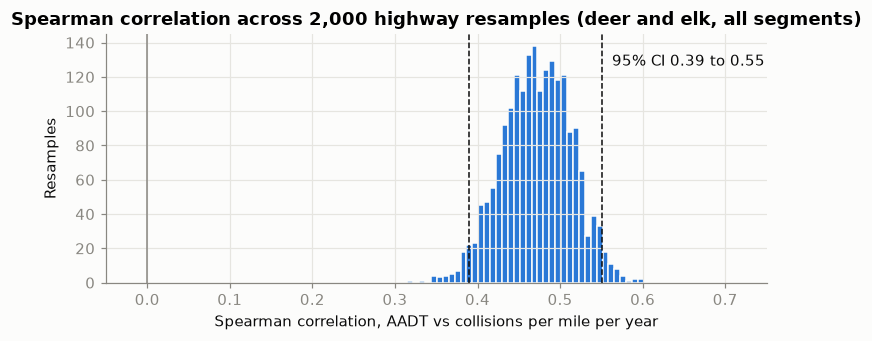

In [4]:
lo, hi = np.percentile(boot_main, [2.5, 97.5])
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(boot_main, bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
for v in (lo, hi):
    ax.axvline(v, color=INK, linewidth=1, linestyle="--")
ax.axvline(0, color=MUTED, linewidth=1)
ax.text(hi, ax.get_ylim()[1] * 0.92, f"  95% CI {lo:.2f} to {hi:.2f}", color=INK, va="top")
ax.set(title="Spearman correlation across 2,000 highway resamples (deer and elk, all segments)",
       xlabel="Spearman correlation, AADT vs collisions per mile per year", ylabel="Resamples")
ax.set_xlim(-0.05, 0.75)
plt.tight_layout()

## Shape of the relationship

A single correlation hides the shape. Segments of at least a quarter mile are split into ten equal-sized groups by AADT. Shorter segments are left out here because one collision on 0.05 miles is a rate of 20.

In [5]:
d = df[~df["is_short"]].copy()
d["aadt_decile"] = pd.qcut(d["hpms_aadt"], 10)
deciles = d.groupby("aadt_decile", observed=True).agg(
    segments=("rate_deer_elk", "size"),
    aadt_median=("hpms_aadt", "median"),
    mean_rate=("rate_deer_elk", "mean"),
    median_rate=("rate_deer_elk", "median"),
    share_zero=("rate_deer_elk", lambda s: (s == 0).mean()),
)
deciles.style.format({"aadt_median": "{:,.0f}", "mean_rate": "{:.2f}", "median_rate": "{:.2f}",
                      "share_zero": "{:.0%}"})

,segments,aadt_median,mean_rate,median_rate,share_zero
aadt_decile,,,,,
"(16.999, 269.0]",772,175,0.08,0.00,57%
"(269.0, 482.0]",726,362,0.14,0.09,40%
"(482.0, 878.2]",730,638,0.33,0.18,26%
"(878.2, 1689.6]",743,"1,179",0.54,0.27,17%
"(1689.6, 2752.97]",743,"2,015",0.70,0.36,16%
"(2752.97, 4360.2]",742,"3,444",0.97,0.64,8%
"(4360.2, 6612.0]",746,"5,480",1.11,0.73,7%
"(6612.0, 11673.0]",742,"8,598",1.35,0.82,7%
"(11673.0, 19730.512]",740,"14,356",1.26,0.82,10%


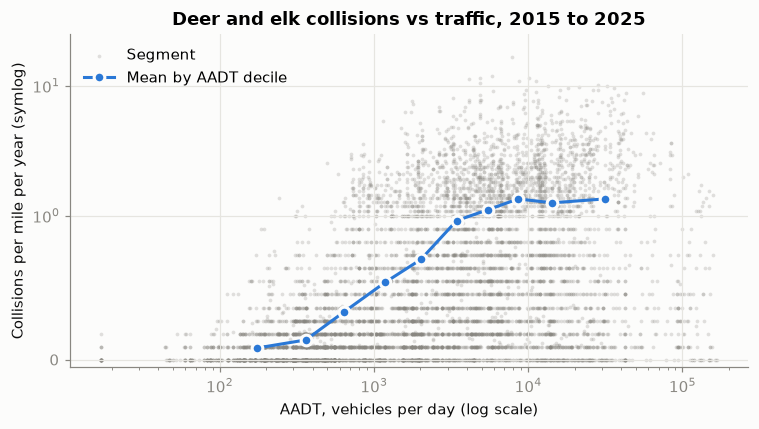

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(d["hpms_aadt"], d["rate_deer_elk"], s=6, color=MUTED, alpha=0.25, linewidths=0,
           label="Segment")
ax.plot(deciles["aadt_median"], deciles["mean_rate"], color=BLUE, linewidth=2, marker="o",
        markersize=7, markeredgecolor="#fcfcfb", markeredgewidth=2, label="Mean by AADT decile")
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=1)
ax.set_ylim(-0.05, 25)
ax.set(title="Deer and elk collisions vs traffic, 2015 to 2025",
       xlabel="AADT, vehicles per day (log scale)",
       ylabel="Collisions per mile per year (symlog)")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()

## Within a highway

Busy highways could simply run through different country than quiet ones. To check that the relationship also holds along a single road, Spearman is computed separately for each highway with at least 20 segments.

94 highways, median Spearman 0.30, 78% positive


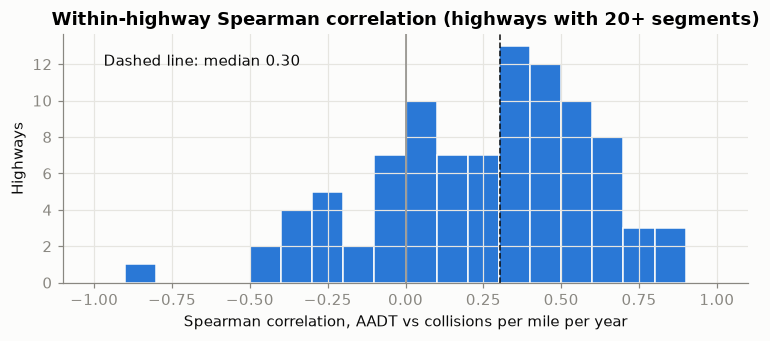

In [7]:
within = pd.Series({
    h: spearmanr(g["hpms_aadt"], g["rate_deer_elk"]).statistic
    for h, g in d.groupby("hwy")
    if len(g) >= 20 and g["hpms_aadt"].nunique() > 3
}).dropna()
print(f"{len(within)} highways, median Spearman {within.median():.2f}, "
      f"{(within > 0).mean():.0%} positive")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(within, bins=np.arange(-1, 1.01, 0.1), color=BLUE, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(0, color=MUTED, linewidth=1)
ax.axvline(within.median(), color=INK, linewidth=1, linestyle="--")
ax.text(-0.97, ax.get_ylim()[1] * 0.92, f"Dashed line: median {within.median():.2f}", color=INK, va="top")
ax.set(title="Within-highway Spearman correlation (highways with 20+ segments)",
       xlabel="Spearman correlation, AADT vs collisions per mile per year", ylabel="Highways")
plt.tight_layout()

## Rural segments only

In [8]:
rural = d[d["hpms_rural_share"] == 1]
r = spearmanr(rural["hpms_aadt"], rural["rate_deer_elk"])
print(f"{len(rural):,} fully rural segments, Spearman {r.statistic:.3f}")

6,205 fully rural segments, Spearman 0.588


## Every feature vs collisions

The same Spearman and highway bootstrap (1,000 resamples) applied to every numeric column, on segments of at least a quarter mile. Identifiers, milepost columns, collision counts, `weather_months` (constant), and the text versions of class columns are left out.

With about 7,400 segments nearly every ordinary p-value is below 0.05, so a feature counts as significant here when its bootstrap interval excludes zero.

`hpms_f_system` and `hpms_access_control` are codes where lower means a bigger road (1 is interstate, 1 is full access control), so their negative correlations point the same way as AADT.

In [9]:
from scipy.stats import kruskal, rankdata

skip = {"segment_id", "hwy", "mkey", "mile", "begin_mp", "end_mp", "is_short", "weather_months",
        "hpms_functional_class", "nlcd_dominant"}
features = [c for c in d.columns if c not in skip and not c.startswith(("coll_", "rate_", "aadt_"))]

d_all = d.reset_index(drop=True)
rows_by_hwy = d_all.groupby("hwy").indices
hwys = np.array(list(rows_by_hwy))
draws = [np.concatenate([rows_by_hwy[h] for h in rng.choice(hwys, len(hwys))]) for _ in range(1000)]


def spearman_ci(x, y):
    """Spearman on non-missing pairs, with a highway-bootstrap 95% interval."""
    ok = ~(np.isnan(x) | np.isnan(y))
    if np.unique(x[ok]).size < 2:
        return np.nan, np.nan, np.nan, int(ok.sum())
    stats = []
    for s in draws:
        xs, ys = x[s], y[s]
        m = ~(np.isnan(xs) | np.isnan(ys))
        with np.errstate(invalid="ignore"):  # a resample can hold one value of a sparse column
            stats.append(np.corrcoef(rankdata(xs[m]), rankdata(ys[m]))[0, 1])
    lo, hi = np.nanpercentile(stats, [2.5, 97.5])
    return spearmanr(x[ok], y[ok]).statistic, lo, hi, int(ok.sum())


rows = []
for f in features:
    x = d_all[f].astype(float).to_numpy()
    rho, lo, hi, n = spearman_ci(x, d_all["rate_deer_elk"].to_numpy())
    rho_all = spearmanr(x, d_all["rate_all"], nan_policy="omit").statistic if not np.isnan(rho) else np.nan
    rows.append({"feature": f, "n": n, "spearman_deer_elk": rho, "ci_low": lo, "ci_high": hi,
                 "spearman_all_animals": rho_all, "significant": bool(lo > 0 or hi < 0)})

corr = (pd.DataFrame(rows).dropna(subset=["spearman_deer_elk"])
        .sort_values("spearman_deer_elk", key=abs, ascending=False).reset_index(drop=True))
print(f"{len(corr)} features, {corr['significant'].sum()} with a bootstrap interval excluding zero")
print("Not computed (constant on segments of at least 0.25 mi):",
      sorted(set(features) - set(corr["feature"])))
corr.style.format({"spearman_deer_elk": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}",
                   "spearman_all_animals": "{:.3f}"}).hide(axis="index")

50 features, 26 with a bootstrap interval excluding zero
Not computed (constant on segments of at least 0.25 mi): ['panel_borrow_m']


feature,n,spearman_deer_elk,ci_low,ci_high,spearman_all_animals,significant
hpms_aadt,7427,0.491,0.406,0.562,0.572,True
hpms_log_aadt,7427,0.491,0.406,0.562,0.572,True
hpms_f_system,7427,-0.451,-0.535,-0.358,-0.489,True
nlcd_developed,7427,0.367,0.280,0.437,0.436,True
hpms_lanes,7427,0.289,0.166,0.389,0.339,True
pop_density_per_km2,7427,0.256,0.162,0.343,0.334,True
hpms_access_control,7427,-0.233,-0.363,-0.049,-0.278,True
nlcd_wetland,7427,0.219,0.120,0.305,0.222,True
gbif_deer,7427,0.211,0.128,0.287,0.238,True
gbif_hawk,7427,0.187,0.112,0.259,0.248,True


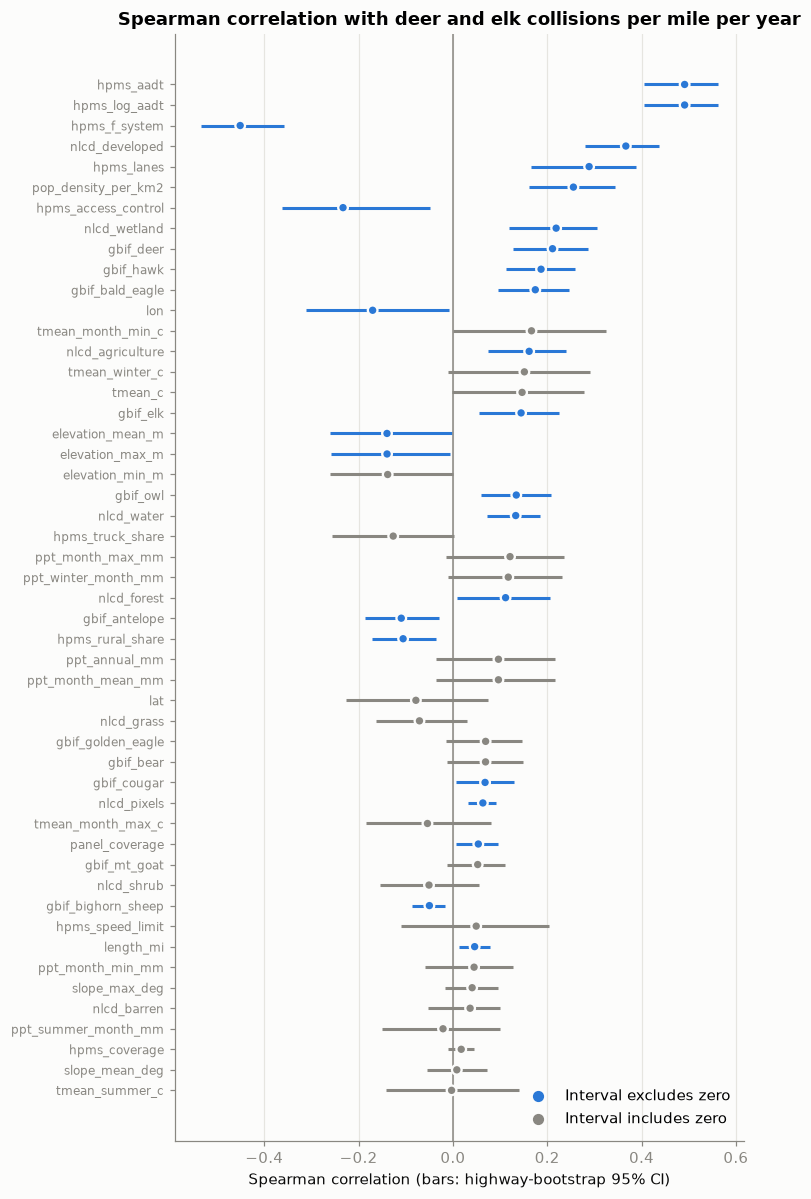

In [10]:
plot = corr.iloc[::-1]
colors = np.where(plot["significant"], BLUE, MUTED)
y = np.arange(len(plot))

fig, ax = plt.subplots(figsize=(7, 11))
ax.hlines(y, plot["ci_low"], plot["ci_high"], color=colors, linewidth=2)
ax.scatter(plot["spearman_deer_elk"], y, color=colors, s=40, edgecolors="#fcfcfb", linewidths=1.5, zorder=3)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, plot["feature"], fontsize=8)
ax.grid(axis="y", visible=False)
ax.set(title="Spearman correlation with deer and elk collisions per mile per year",
       xlabel="Spearman correlation (bars: highway-bootstrap 95% CI)")
ax.scatter([], [], color=BLUE, s=40, label="Interval excludes zero")
ax.scatter([], [], color=MUTED, s=40, label="Interval includes zero")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()

`nlcd_dominant` is a category, so the groups are compared with a Kruskal-Wallis test instead of a correlation.

In [11]:
groups = d.groupby("nlcd_dominant")["rate_deer_elk"]
print(f"Kruskal-Wallis p = {kruskal(*[g.to_numpy() for _, g in groups]).pvalue:.1e}")
groups.agg(segments="size", mean_rate="mean", median_rate="median").sort_values("median_rate", ascending=False).round(2)

Kruskal-Wallis p = 1.6e-114


,segments,mean_rate,median_rate
nlcd_dominant,,,
developed,1617,1.34,0.73
wetland,232,0.94,0.64
water,70,0.64,0.55
agriculture,1576,0.79,0.36
forest,1778,0.60,0.27
shrub,1404,0.55,0.18
grass,747,0.41,0.09
barren,3,0.00,0.00


## Busy segments with few reported collisions

If traffic goes with more collisions, segments with high traffic and few reports are candidates for under-reporting. A low count has two possible explanations: few animals are hit there, or crews are not logging them. This table cannot tell those apart, so the segments below are leads to check against another source, such as crash reports or state police records.

Elevation is not used here. Higher segments report fewer collisions, not more:

In [12]:
d.groupby(pd.qcut(d["elevation_mean_m"], 5), observed=True)["rate_deer_elk"].agg(
    mean_rate="mean", median_rate="median").round(2).rename_axis("elevation_mean_m quintile")

,mean_rate,median_rate
elevation_mean_m quintile,,
"(0.459, 73.751]",0.76,0.45
"(73.751, 296.66]",0.87,0.45
"(296.66, 800.57]",0.80,0.36
"(800.57, 1245.574]",0.86,0.27
"(1245.574, 1941.413]",0.62,0.18


The comparison group is rural segments (at least 90% outside urban areas) in the top half of traffic. Urban segments are left out because few deer or elk live there. The question is how many of these segments have **zero** deer or elk reports in 11 years, and whether those segments have signs of animals nearby.

In [13]:
natural = ["nlcd_forest", "nlcd_shrub", "nlcd_grass", "nlcd_agriculture", "nlcd_wetland"]
d["deer_elk_count"] = d["coll_deer_elk_2015_2020"] + d["coll_deer_elk_2021_2025"]
d["gbif_deer_elk"] = d["gbif_deer"] + d["gbif_elk"]

busy_rural = d[(d["hpms_rural_share"] >= 0.9) & (d["hpms_aadt"] >= d["hpms_aadt"].median())]
zero = busy_rural[busy_rural["deer_elk_count"] == 0]
print(f"Busy rural segments: {len(busy_rural):,} (AADT >= {d['hpms_aadt'].median():,.0f}), "
      f"mean rate {busy_rural['rate_deer_elk'].mean():.2f} per mile per year")
print(f"Zero deer/elk reports in 2015-2025: {len(zero)} ({len(zero) / len(busy_rural):.1%})")
print(f"  with deer or elk sightings within 5 km: {(zero['gbif_deer_elk'] > 0).sum()}")
print(f"  at least half natural or farm land: {(zero[natural].sum(axis=1) >= 0.5).sum()}")

Busy rural segments: 2,561 (AADT >= 2,753), mean rate 1.18 per mile per year
Zero deer/elk reports in 2015-2025: 148 (5.8%)
  with deer or elk sightings within 5 km: 88
  at least half natural or farm land: 127


Single zero segments can be chance. A whole highway reporting far below its traffic level is a stronger sign. The table lists mostly rural highways with at least 10 segments and median AADT of at least 2,000, lowest rate first. Highway numbers are ODOT's internal numbers, not signed route numbers.

In [14]:
by_hwy = d.groupby("hwy").agg(
    segments=("deer_elk_count", "size"),
    miles=("length_mi", "sum"),
    collisions=("deer_elk_count", "sum"),
    share_zero=("deer_elk_count", lambda s: (s == 0).mean()),
    median_aadt=("hpms_aadt", "median"),
    rural_share=("hpms_rural_share", "mean"),
    deer_elk_sightings=("gbif_deer_elk", "sum"),
)
by_hwy["rate_per_mile_yr"] = by_hwy["collisions"] / by_hwy["miles"] / YEARS
low = by_hwy[(by_hwy["segments"] >= 10) & (by_hwy["rural_share"] >= 0.8) & (by_hwy["median_aadt"] >= 2000)]
low.sort_values("rate_per_mile_yr").head(10).style.format({
    "miles": "{:.1f}", "share_zero": "{:.0%}", "median_aadt": "{:,.0f}", "rural_share": "{:.2f}",
    "rate_per_mile_yr": "{:.2f}"})

,segments,miles,collisions,share_zero,median_aadt,rural_share,deer_elk_sightings,rate_per_mile_yr
hwy,,,,,,,,
161,34,33.3,101,18%,"5,907",0.89,71,0.28
281,19,18.9,64,16%,"2,092",0.94,69,0.31
032,25,25.0,97,4%,"2,241",1.00,45,0.35
361,12,11.6,47,17%,"2,785",0.83,144,0.37
042,70,68.4,300,13%,"2,776",1.00,266,0.40
211,26,25.3,125,0%,"2,192",1.00,91,0.45
018,88,86.8,450,9%,"3,532",0.97,843,0.47
053,61,60.1,319,20%,"4,364",0.94,46,0.48
212,22,21.4,128,18%,"4,266",0.94,33,0.54


Zero segments on interstates are mostly fully access-controlled sections, which are often fenced, so they are weaker candidates.

In [15]:
zero.groupby("hpms_functional_class").agg(
    segments=("segment_id", "size"),
    full_access_control=("hpms_access_control", lambda s: (s == 1).mean()),
).sort_values("segments", ascending=False).style.format({"full_access_control": "{:.0%}"})

,segments,full_access_control
hpms_functional_class,,
principal_arterial,63,2%
minor_arterial,60,0%
interstate,17,100%
major_collector,8,0%


A change in reporting over time would show up as segments that report steadily in one window and not at all in the other.

In [16]:
stopped = d[(d["coll_deer_elk_2015_2020"] >= 12) & (d["coll_deer_elk_2021_2025"] == 0)]
started = d[(d["coll_deer_elk_2015_2020"] == 0) & (d["coll_deer_elk_2021_2025"] >= 10)]
print(f"At least 2 per year in 2015-2020, then none in 2021-2025: {len(stopped)} segments")
print(f"None in 2015-2020, then at least 2 per year in 2021-2025: {len(started)} segments")

At least 2 per year in 2015-2020, then none in 2021-2025: 4 segments
None in 2015-2020, then at least 2 per year in 2021-2025: 0 segments


Map of the busy rural segments with zero reports, and of every segment on the ten low-rate highways in the table above. Points are segment midpoints (`lat`, `lon`).

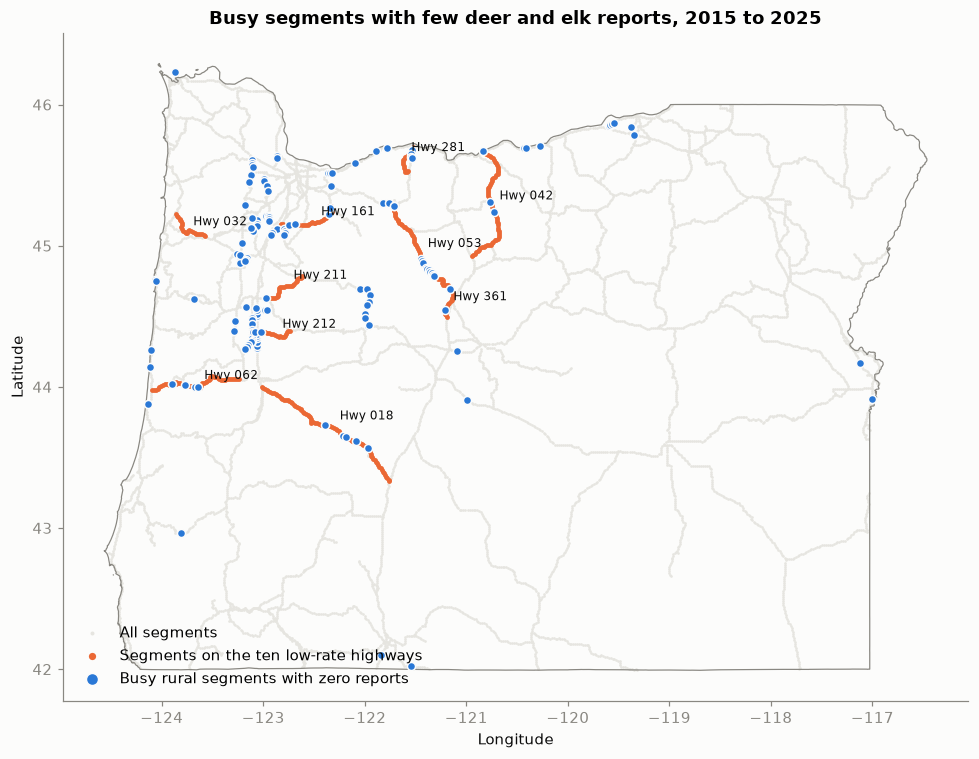

In [17]:
import geopandas as gpd

ORANGE = "#eb6834"
states = gpd.read_file("../data/raw/cb_2023_us_state_500k.zip")
oregon = states[states["STUSPS"] == "OR"]
low_hwys = low.sort_values("rate_per_mile_yr").head(10).index
on_low = d[d["hwy"].isin(low_hwys)]

fig, ax = plt.subplots(figsize=(9, 7.5))
oregon.boundary.plot(ax=ax, color=MUTED, linewidth=0.8)
ax.scatter(d["lon"], d["lat"], s=3, color=GRID, linewidths=0, label="All segments")
ax.scatter(on_low["lon"], on_low["lat"], s=10, color=ORANGE, linewidths=0,
           label="Segments on the ten low-rate highways")
ax.scatter(zero["lon"], zero["lat"], s=28, color=BLUE, edgecolors="#fcfcfb", linewidths=1, zorder=3,
           label="Busy rural segments with zero reports")
for h, g in on_low.groupby("hwy"):
    mid = g.iloc[len(g) // 2]
    ax.annotate(f"Hwy {h}", (mid["lon"], mid["lat"]), xytext=(5, 5), textcoords="offset points",
                fontsize=8, color=INK)
ax.set_aspect(1 / np.cos(np.radians(44)))
ax.set(title="Busy segments with few deer and elk reports, 2015 to 2025", xlabel="Longitude", ylabel="Latitude")
ax.grid(False)
ax.legend(frameon=False, loc="lower left", markerscale=1.5)
plt.tight_layout()

## Findings

- Traffic and deer and elk collision rates are positively correlated (Spearman about 0.48). The highway bootstrap interval stays well above zero, so the relationship holds after accounting for segments on the same highway.
- The rate rises steeply up to roughly 7,000 vehicles per day and then levels off. On the busiest decile the median rate falls and the share of segments with no collisions rises, likely urban segments and fenced interstates.
- The relationship holds within highways (median Spearman about 0.30) and is stronger on fully rural segments.
- Across all features, the strongest correlations are traffic and road size (AADT, road class, lanes, access control), followed by developed land, population density, wetland share, and deer sightings. Terrain, precipitation, and summer temperature show little or no correlation. Many of the top features rise and fall together, so these correlations do not show which one drives collisions.
- Of 2,561 busy rural segments, 148 (6%) have no deer or elk reports in 11 years, and 88 of those have deer or elk sightings within 5 km. Several mostly rural highways report at a third of the typical rate. These are candidates for under-reporting to check against another source.

## Limitations

- These are correlations. They do not control for land cover, terrain, or where deer and elk live, any of which could move with traffic.
- The decile table describes the curve and does not test it.
- AADT is a 2024 snapshot applied to collisions from 2015 to 2025.
- Collisions are carcasses logged by ODOT crews, and reporting effort may vary by district.